# 16 - Borehole Image (FMI) Processing

**Part B - Petrophys Curriculum**

A Fullbore Formation MicroImager (FMI) is not an ordinary scalar log. Instead of one value per
depth, each depth samples the borehole wall with **many microresistivity buttons** spread
across a set of pads and flaps. The raw recording is a strip of *buttons*, not a picture:
its columns are sensor positions on the tool, not compass directions. A recognisable
image only appears once every button is **rotated to its true azimuth** using the tool's
navigation curve and then contrast-enhanced (equalized).

This lesson walks through the `petrophys.interpretation.borehole_imaging` FMI pipeline end to end on a
**real processed FMI** from the **Daydream 1** well (QGC, ATP 645, Bowen Basin,
Queensland) - public well-completion-report data.

## Learning goals

- Understand what an FMI records: pads/flaps, buttons, and the `P1AZ` navigation curve.
- Load image logs with `read_borehole_image_las` / `read_borehole_image_dlis` /
  `read_fmi_dlis`, and hold them in a `BoreholeImageData` container.
- Attach well navigation (`with_navigation`) and rotate buttons to compass azimuth
  (`orient_to_azimuth`) - the step that turns a strip into an image.
- Contrast-enhance with **static** vs **dynamic** equalization
  (`equalize_static` / `equalize_dynamic`) and know when to pick which.
- Measure `azimuthal_coverage` and display with `plot_fmi` /
  `visualization.create_fmi_panel`.

## Why this matters

FMI images are the primary tool for **structural and sedimentological dip picking**:
a planar bed or fracture that cuts the borehole at an angle projects onto the unrolled
0-360 degree image as a **sinusoid**. The amplitude of that sinusoid encodes dip
magnitude and its trough points down-dip azimuth. None of this is visible in the raw
per-button strip - it emerges only after orientation. Equalization then trades
large-scale contrast against fine textural detail so an interpreter can see both thick
units and thin laminae.

### Prerequisites

This lesson assumes you are comfortable with `pp.read` / `read_las` and the
`Well`/`Curve` model from the Part A foundations lessons. No prior imaging
knowledge is required.

It needs two things beyond the base install:

1. **The DLIS extra.** Image logs are read from DLIS files with `dlisio`:
   `pip install "petrophys[dlis]"`.
2. **The processed Daydream 1 FMI image** (a DLIS file of about 110 MB, public
   Queensland well-completion data). It is stored in the Petrophys repository
   with **Git LFS** and is deliberately *not* part of the installable wheel.
   In a clone of the repository run `git lfs pull`; the lesson then finds the
   file automatically. Otherwise set the environment variable
   `PETROPHYS_FMI_DLIS` to the path of that file (or of another processed FMI
   DLIS) before you start Jupyter.

If either is missing, the loading cell in Section 1 stops with a message that
says which one.

In [1]:
%matplotlib inline
from petrophys.visualization import use_plot_style
use_plot_style()
import numpy as np
import matplotlib.pyplot as plt

import petrophys
from petrophys.interpretation.borehole_imaging import (
    BoreholeImageData,
    read_borehole_image_las,
    read_borehole_image_dlis,
    read_fmi_dlis,
    with_navigation,
    get_navigation,
    orient_to_azimuth,
    equalize_static,
    equalize_dynamic,
    azimuthal_coverage,
    plot_fmi,
    fmi_colormap,
)
from petrophys.interpretation.borehole_imaging.fmi import ARRAY_ORDER, ARRAY_OFFSET_DEG, ARRAY_SPACING_DEG
from petrophys.visualization import create_fmi_panel

print("petrophys", petrophys.__version__)
print("FMI array order (pads/flaps):", ARRAY_ORDER)
print("array spacing:", ARRAY_SPACING_DEG, "deg  (8 arrays around 360 deg)")
print("array azimuth offsets from pad 1:")
for name, off in ARRAY_OFFSET_DEG.items():
    print("  %-5s -> %5.1f deg" % (name, off))

petrophys 3.0.0
FMI array order (pads/flaps): ('FMPA', 'FMFA', 'FMPB', 'FMFB', 'FMPC', 'FMFC', 'FMPD', 'FMFD')
array spacing: 45.0 deg  (8 arrays around 360 deg)
array azimuth offsets from pad 1:
  FMPA  ->   0.0 deg
  FMFA  ->  45.0 deg
  FMPB  ->  90.0 deg
  FMFB  -> 135.0 deg
  FMPC  -> 180.0 deg
  FMFC  -> 225.0 deg
  FMPD  -> 270.0 deg
  FMFD  -> 315.0 deg


## 1. How the readers map onto data sources

`petrophys.interpretation.borehole_imaging` offers three entry points, all returning a `BoreholeImageData`:

| Function | Source | Typical use |
| --- | --- | --- |
| `read_fmi_dlis(path)` | processed FMI DLIS | **preferred** - reads image channels *and* navigation (`P1AZ`, `HAZI`, `DEVI`, `RB`), interpolating nav onto image depth |
| `read_borehole_image_dlis(path)` | any image DLIS frame | generic electrical/acoustic image, auto-detects array channels |
| `read_borehole_image_las(path)` | flattened LAS export | LAS can't hold DLIS arrays, so buttons arrive as `FMPA_0 ... FMPA_23`; this regroups them into a 2D image |

Below we load the Daydream 1 processed FMI with the preferred entry point,
`read_fmi_dlis`. The other two readers follow the same pattern on their own
sources.

In [2]:
import os
from importlib.util import find_spec
from pathlib import Path
from petrophys.datasets import integration_fixture

if find_spec("dlisio") is None:
    raise ImportError('Reading DLIS needs the DLIS extra: pip install "petrophys[dlis]"')

# PETROPHYS_FMI_DLIS overrides the Git LFS copy in the repository.
configured_path = os.environ.get("PETROPHYS_FMI_DLIS")
fmi_path = (Path(configured_path).expanduser() if configured_path else
            integration_fixture("daydream1_fmi_processed_dynamic_image.dlis"))
# Without `git lfs pull` the repository holds only a tiny text pointer file.
if not fmi_path.is_file() or fmi_path.stat().st_size < 1024:
    raise FileNotFoundError(
        "The processed FMI DLIS is missing: run 'git lfs pull' in the repository, "
        "or set PETROPHYS_FMI_DLIS to the path of a processed FMI DLIS."
    )

data = read_fmi_dlis(fmi_path)

step_mm = 1000.0 * float(np.nanmedian(np.abs(np.diff(data.depth))))
print("well              :", data.metadata.get("well"))
print("field             :", data.metadata.get("field"))
print("image shape       :", data.image.shape, "(depth rows x buttons)")
print("channels          :", data.channel_names)
print("buttons per array :", data.samples_per_channel)
print("depth             : %.1f - %.1f %s  (%.1f mm sampling)"
      % (np.nanmin(data.depth), np.nanmax(data.depth), data.depth_unit, step_mm))
print("navigation curves :", sorted(get_navigation(data)))

well              : Daydream 1
field             : ATP 645
image shape       : (500788, 192) (depth rows x buttons)
channels          : ['FMPA', 'FMFA', 'FMPB', 'FMFB', 'FMPC', 'FMFC', 'FMPD', 'FMFD']
buttons per array : [24, 24, 24, 24, 24, 24, 24, 24]
depth             : 2869.0 - 4141.0 m  (2.5 mm sampling)
navigation curves : ['DEVI', 'HAZI', 'P1AZ', 'RB']


## 2. Pads, flaps, buttons and navigation

The FMI carries **4 pads** (`FMPA-FMPD`) and **4 flaps** (`FMFA-FMFD`), each with
24 microresistivity buttons: 8 arrays x 24 = **192 columns** in the image. Each
array sits at a fixed azimuthal offset from pad 1 (`ARRAY_OFFSET_DEG`, printed in
the setup cell), and the tool's own compass curve `P1AZ` records where pad 1
points at every depth. `read_fmi_dlis` loaded the navigation (`P1AZ`, `RB`,
`DEVI`, `HAZI`) and interpolated it onto the image depth grid for us.

At 2.5 mm sampling the full log is half a million rows, so we cut a **working
window** with `filter_by_depth` - which carries the navigation along - and do
everything on the window.

In [3]:
nav = get_navigation(data)
p1az = np.asarray(nav["P1AZ"], dtype=float)
print("P1AZ (pad-1 azimuth): %.0f - %.0f deg across the log -> the tool rotates"
      % (np.nanmin(p1az), np.nanmax(p1az)))
print("hole deviation DEVI : median %.1f deg" % float(np.nanmedian(nav["DEVI"])))

zoom = data.filter_by_depth(2900.0, 2910.0)
print()
print("working window: %d rows x %d buttons over 10 m" % zoom.image.shape)

P1AZ (pad-1 azimuth): 0 - 360 deg across the log -> the tool rotates
hole deviation DEVI : median 2.1 deg

working window: 3937 rows x 192 buttons over 10 m


### The container and its guarantees

`BoreholeImageData.from_arrays` is the constructor the DLIS/LAS readers call
internally - `samples_per_channel` records which columns belong to which array,
which is exactly what orientation needs. Use it (plus `with_navigation`) when
your image arrives as bare arrays. Depth filtering preserves the attached
navigation, so a window is always orientable if its parent was.

In [4]:
print("n depth samples   :", zoom.n_samples)
print("n borehole samples:", zoom.n_borehole_samples)
print("channels          :", zoom.channel_names)
print("depth range       : %.1f - %.1f %s" % (zoom.top, zoom.bottom, zoom.depth_unit))
print("navigation curves :", sorted(get_navigation(zoom)), "(preserved by filter_by_depth)")

n depth samples   : 3937
n borehole samples: 192
channels          : ['FMPA', 'FMFA', 'FMPB', 'FMFB', 'FMPC', 'FMFC', 'FMPD', 'FMFD']
depth range       : 2900.0 - 2910.0 m
navigation curves : ['DEVI', 'HAZI', 'P1AZ', 'RB'] (preserved by filter_by_depth)


## 3. The raw strip is not an image

Plot the raw button array as-is. The x-axis is a **borehole sample index**: 192
contiguous button columns in tool order, pad by pad. Notice the vertical seams
where one pad's strip ends and the next begins - each pad looks at a different
part of the wall, so the same bed sits at a slightly different tone and depth in
neighbouring blocks, and as the tool rotates the geology slides between columns.
There is no compass meaning here: dip magnitude and azimuth cannot be read from
this view.

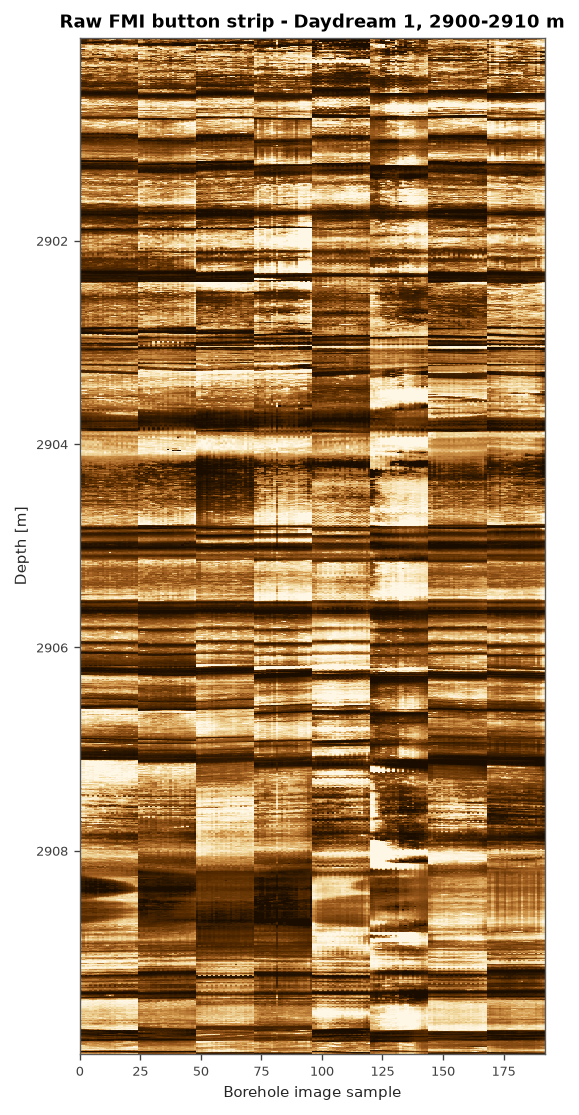

In [5]:
# The raw (un-oriented) strip, rendered by the library plot_fmi. With an
# un-oriented image, plot_fmi labels the x-axis as the borehole sample index
# (NOT a compass direction) - exactly the point here.
ax = plot_fmi(zoom, equalize="static", interpolation="nearest")
ax.set_title("Raw FMI button strip - Daydream 1, 2900-2910 m")
plt.show()

## 4. Orient to azimuth: the key step

`orient_to_azimuth` rotates every button to its true compass azimuth using the
navigation reference (`reference="north"` uses `P1AZ`; `reference="highside"` uses `RB`)
plus each array's fixed offset, then bins the buttons onto a regular 0-360 degree grid.

Crucially, the wedges **between** pads are never imaged, so they are left as `NaN`
(gaps) rather than interpolated - the picture reflects real borehole-wall coverage.
The output is a new `BoreholeImageData` whose single logical channel is `AZIMUTH`.

In [6]:
oriented = orient_to_azimuth(zoom, n_azimuth=180, reference="north")

print("oriented image shape:", oriented.image.shape, "(depth x azimuth bins)")
print("image_type          :", oriented.image_type)
print("oriented flag        :", oriented.metadata.get("oriented"))
print("orientation ref      :", oriented.metadata.get("orientation_reference"))
print("arrays used          :", oriented.metadata.get("used_arrays"))

oriented image shape: (3937, 180) (depth x azimuth bins)
image_type          : fmi_oriented
oriented flag        : True
orientation ref      : north
arrays used          : ['FMPA', 'FMFA', 'FMPB', 'FMFB', 'FMPC', 'FMFC', 'FMPD', 'FMFD']


Now plot the oriented image with `plot_fmi`. The x-axis carries a **compass
scale** (N-E-S-W-N): every button now sits at its true azimuth, so beds line up
across pads as continuous bands. The white wedges are the un-imaged gaps between
pads - and they now **spiral with depth**, because the gaps sit at fixed
positions on the rotating tool, so their compass position drifts as the tool
turns. Daydream 1's coal-measure bedding is close to horizontal here, so beds
cross the unrolled image as gently waving bands rather than deep sinusoids. A
steeply dipping surface would trace a full sinusoid whose trough points
down-dip; a feature aligned with the borehole axis (Exercise 1, near
4055-4058 m) instead runs straight down the image.

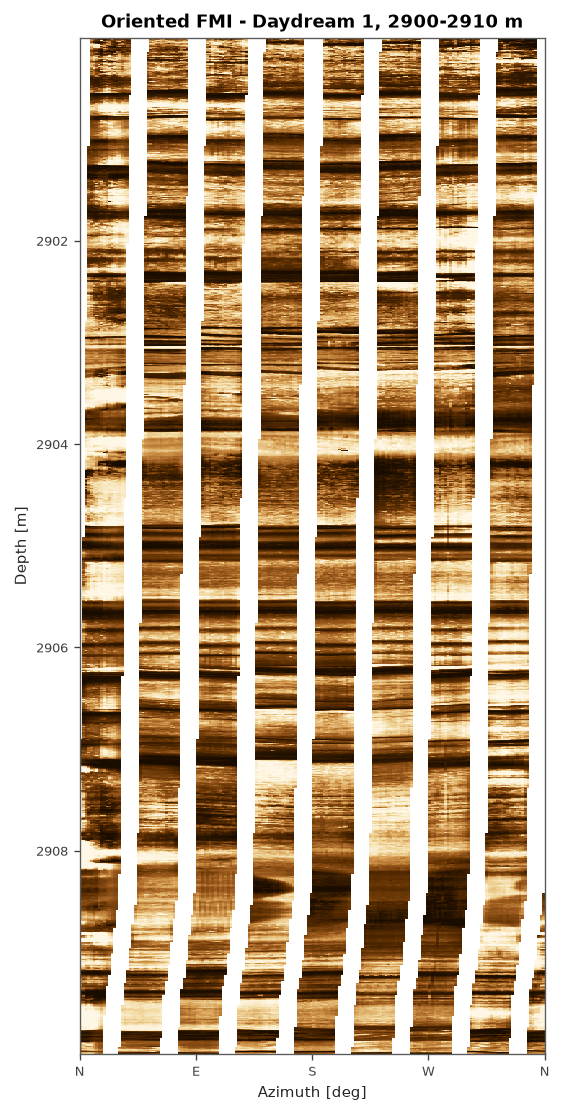

In [7]:
# plot_fmi detects the oriented image and draws a compass (N-E-S-W-N) x-axis.
ax = plot_fmi(oriented, equalize="static", interpolation="nearest")
ax.set_title("Oriented FMI - Daydream 1, 2900-2910 m")
plt.show()

### Azimuthal coverage

`azimuthal_coverage` reports, per depth, the fraction of the 360 degrees
actually imaged - the un-imaged inter-pad wedges are the missing fraction. On
this window Daydream 1 images about 70% of the circumference. One number tells
the story, so we print it rather than plot it; note that the library computes
coverage from the tool's fixed pad geometry, so it does not respond to hole
enlargement (a washout hurts image *quality* long before it changes this
number).

In [8]:
coverage = azimuthal_coverage(oriented)
print("azimuthal coverage: mean=%.2f  min=%.2f  max=%.2f"
      % (np.nanmean(coverage), np.nanmin(coverage), np.nanmax(coverage)))

azimuthal coverage: mean=0.70  min=0.69  max=0.71


## 5. Static vs dynamic equalization

The industry-standard FMI presentation is a **dual display**: a **static**
image (one percentile stretch over the whole interval, preserving absolute
contrast so a resistive unit stays bright everywhere) next to a **dynamic**
image (a sliding-window stretch that surfaces thin-bed texture inside each
unit). Interpreters read structure and unit-to-unit contrast off the static
and fine texture off the dynamic. In `petrophys`, `equalize_static` /
`equalize_dynamic` implement the two schemes and `plot_fmi(equalize=...)`
selects one.

We do not render that comparison here, deliberately: this deliverable is
already the service company's **dynamically processed** product (the button
values were locally re-scaled downhole), so re-equalizing it either way
produces two nearly identical images - a figure that demonstrates nothing.
The true static/dynamic contrast needs the statically normalised deliverable
or the raw acquisition; vendors ship both on request.

## 6. One-call panel: `create_fmi_panel`

For a quick look, `petrophys.visualization.create_fmi_panel` wraps the whole thing:
pass the **raw** (un-oriented) `BoreholeImageData` with `orient=True` and it will detect
the navigation curve, orient internally, equalize, and render a titled figure. Passing
`orient=False` shows the raw strip. `equalize` selects `"static"`, `"dynamic"`, or
`"none"`.

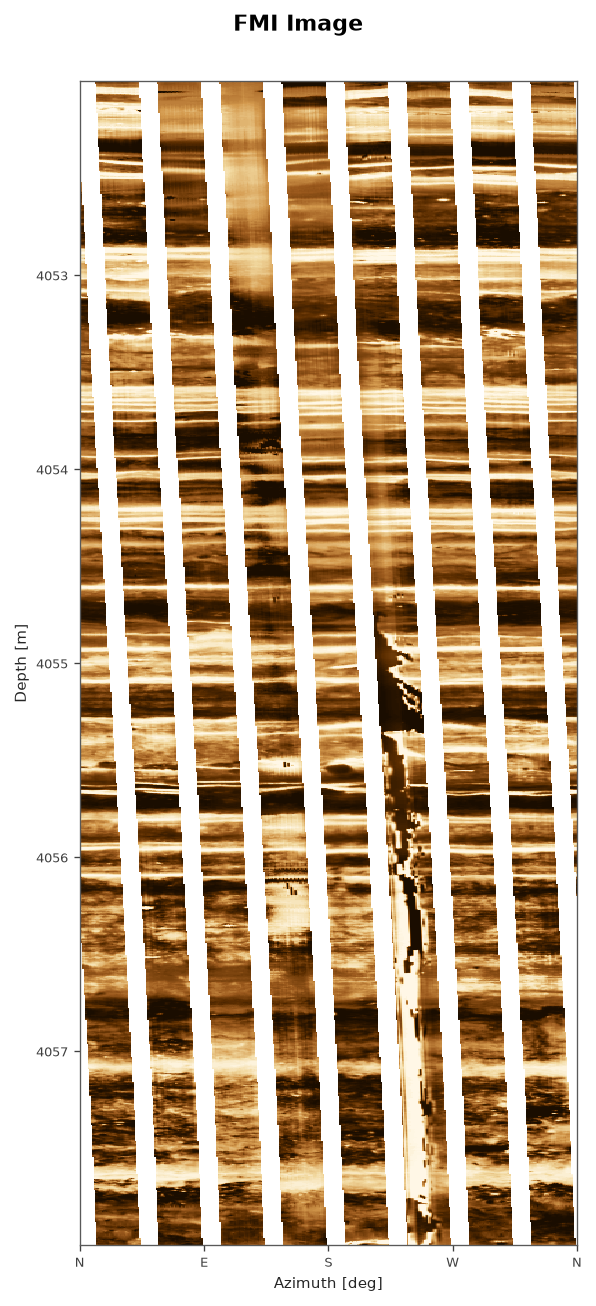

In [9]:
# One call: filter to the window, orient using the attached navigation,
# equalize dynamically, render. The window holds the steep conductive event
# from Exercise 1. (Passing orient=False would show the raw strip instead -
# that view is already covered in Section 3.)
create_fmi_panel(data, depth_range=(4052.0, 4058.0), orient=True, equalize="dynamic")
plt.show()

## Pitfalls & parameter choices

- **Filter before you orient.** A processed FMI is huge (here 500,788 rows x 192
  buttons at 2.5 mm). Cut a working window with `filter_by_depth` first;
  orienting the full log burns memory and time on wall you are not interpreting.

- **Orientation needs navigation.** `orient_to_azimuth(reference="north")` requires
  `P1AZ`; `reference="highside"` requires `RB`. `read_fmi_dlis` loads these for you and
  interpolates them onto image depth. If you build data by hand, attach them with
  `with_navigation` or orientation raises.
- **Gaps are real, not missing.** Inter-pad wedges stay `NaN` on purpose. Do not
  in-fill them before dip picking - the empty azimuths are genuine no-coverage.
- **`n_azimuth` is a display grid, not resolution.** Choosing 360 vs 180 bins only sets
  how finely buttons are re-binned; it cannot create coverage the tool never recorded.
- **Static vs dynamic is a trade, not a ranking.** Static keeps absolute contrast;
  dynamic surfaces texture. Interpreters routinely view both - and note that a
  *processed dynamic* deliverable (like this file) cannot be turned back into a
  static display; request both products from the vendor.
- **`read_borehole_image_las` regroups flattened curves** (`FMPA_0..FMPA_23`); make sure
  the exporter used a consistent `PREFIX_index` naming or pass `channel_prefixes`.

## Recap

- An FMI records microresistivity **buttons on pads/flaps**, not compass-referenced
  pixels; the raw strip is not yet an image.
- `BoreholeImageData` holds depth, the 2D button array, and which columns belong to which
  array - everything `orient_to_azimuth` needs.
- **Orientation** (`orient_to_azimuth`, using `P1AZ` + fixed offsets) is what turns the
  strip into a compass-referenced image where a dipping bed reads as a **sinusoid**.
- **Equalization** (`equalize_static` vs `equalize_dynamic`) tunes contrast; **coverage**
  (`azimuthal_coverage`) tells you how much of the wall was actually seen.
- `plot_fmi` and `create_fmi_panel` render the result in one call.

## Try it yourself

> **Exercise 1.** Render the panel window 4052-4058 m with `n_azimuth=360` and
> study the dark (conductive) near-vertical trace at roughly WSW azimuth, with a
> fainter partner about 180 degrees away. It does not cross the image as a
> sinusoid - it runs along the borehole axis. What kind of feature does that, and
> what does its azimuth tell you? (Hint: drilling-induced tensile fractures form
> 180 degrees apart along the maximum horizontal stress azimuth; a steeply
> dipping natural fracture would instead trace a high-amplitude sinusoid.)
>
> **Exercise 2.** Re-orient the 2900-2910 m window with `reference="highside"`
> (uses `RB`) and compare against the north-referenced image. In a near-vertical
> hole (check the DEVI printout), why is the highside reference less stable?
>
> **Exercise 3.** Re-run `orient_to_azimuth` with `n_azimuth=90` and again with `360`.
> Compare `azimuthal_coverage` - does more bins buy more coverage? Why not?

## What's next

Continue with **17_visualization_masterclass.ipynb**, where `create_fmi_panel` takes its
place alongside the full petrophys plotting gallery: template log viewers, triple combo,
the crossplot family, and specialist NMR/flow-unit panels.